# Projeto Final

### Importando Dados

In [8]:
import pickle

with open('Dados_EEG\dados_EEG1.pkl', mode='rb') as f:
  X_train, y_train, X_test, y_test, CANAIS, TAM_JANELA= pickle.load(f)

print(len(X_train), len(y_train))
print(len(X_test), len(y_test))
print(f"Canais: {CANAIS}")
print(f"Tamanho Janelas: {TAM_JANELA}")

14400 14400
4140 4140
Canais: [32, 9, 11, 13, 38]
Tamanho Janelas: 640


# Arquitetura 1D CNN com Keras

In [ ]:
import tensorflow as tf
import os
os.environ["KERAS_BACKEND"] = "tensorflow"  # Ou "torch"/"jax"
import keras 
from keras import layers

In [10]:
# Camada de Normalização
normalizer = layers.Normalization(axis=-1)
normalizer.adapt(X_train)

### Modelo Próprio 1D CNN

In [ ]:
# Dim entrada/saída
input_shape = [TAM_JANELA, len(CANAIS)]
num_classes = 3

model = keras.Sequential(
    [
        keras.Input(shape=input_shape),
        normalizer,  # adaptada Normalizaçã

        layers.Conv1D(filters=32, kernel_size=32, activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling1D(pool_size=2),
        layers.Dropout(0.3), 

        layers.Conv1D(filters=64, kernel_size=15, activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling1D(pool_size=3),
        layers.Dropout(0.5), 

        layers.Flatten(),
        
        layers.Dense(num_classes),
    ]
)

model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization (Normalization)   │ (None, 640, 5)         │            11 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_8 (Conv1D)               │ (None, 609, 32)        │         5,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 609, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_8 (MaxPooling1D)  │ (None, 304, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 304, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_9 (Conv1D)               │ (None, 290, 64)        │        30,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 290, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_9 (MaxPooling1D)  │ (None, 96, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 96, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 6144)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 3)              │        18,435 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 54,766 (213.93 KB)

 Trainable params: 54,563 (213.14 KB)

 Non-trainable params: 203 (816.00 B)

### Treinamento

In [ ]:
from keras.optimizers import AdamW
import numpy as np
from sklearn.utils import class_weight

model.compile(
    optimizer= AdamW (learning_rate=0.001, weight_decay=1e-4),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

# Define os callbacks
from keras.callbacks import EarlyStopping, ReduceLROnPlateau
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=12, 
    restore_best_weights=True)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss', 
    factor=0.1, 
    patience=4, 
    min_lr=1e-6)

class_weights = {
    0: 1.0,  #  classe Parado
    1: 1.0,  #  classe Direita
    2: 1.0   #  classe Esquerda
}

auto_weights = class_weight.compute_class_weight(
    'balanced',
    classes=np.unique(y_train),
    y=y_train
)
class_weights_auto = dict(enumerate(auto_weights))
print(f"Pesos calculados automaticamente: {class_weights_auto}")

Pesos calculados automaticamente: {0: np.float64(0.6666666666666666), 1: np.float64(1.321949876067199), 2: np.float64(1.3449145418884842)}


Treinando ...

In [37]:
# Treina modelo
model.fit(X_train, y_train, 
          epochs=40, 
          batch_size=32, 
          validation_data=(X_test, y_test), 
          callbacks=[early_stopping, reduce_lr], # callbacks
          class_weight=class_weights)  


# Avaliar modelo
loss, accuracy = model.evaluate(X_test, y_test)
print(f'Acurácia: {accuracy}')

Epoch 1/40
450/450 ━━━━━━━━━━━━━━━━━━━━ 18s 35ms/step - accuracy: 0.4899 - loss: 2.0745 - val_accuracy: 0.5133 - val_loss: 1.6921 - learning_rate: 0.0010
Epoch 2/40
450/450 ━━━━━━━━━━━━━━━━━━━━ 16s 36ms/step - accuracy: 0.5434 - loss: 1.7377 - val_accuracy: 0.5507 - val_loss: 1.5941 - learning_rate: 0.0010
Epoch 3/40
450/450 ━━━━━━━━━━━━━━━━━━━━ 16s 36ms/step - accuracy: 0.5581 - loss: 1.5007 - val_accuracy: 0.5944 - val_loss: 1.1642 - learning_rate: 0.0010
Epoch 4/40
450/450 ━━━━━━━━━━━━━━━━━━━━ 16s 36ms/step - accuracy: 0.5828 - loss: 1.3406 - val_accuracy: 0.6128 - val_loss: 1.0419 - learning_rate: 0.0010
Epoch 5/40
450/450 ━━━━━━━━━━━━━━━━━━━━ 14s 31ms/step - accuracy: 0.5872 - loss: 1.2373 - val_accuracy: 0.6056 - val_loss: 1.0160 - learning_rate: 0.0010
Epoch 6/40
450/450 ━━━━━━━━━━━━━━━━━━━━ 14s 30ms/step - accuracy: 0.5930 - loss: 1.1366 - val_accuracy: 0.5940 - val_loss: 0.9538 - learning_rate: 0.0010
Epoch 7/40
450/450 ━━━━━━━━━━━━━━━━━━━━ 13s 28ms/step - accuracy: 0.6097 - l

In [6]:
# Dados extraídos manualmente do log de 36 épocas
history_data = {
    'accuracy': [
        0.4572, 0.5325, 0.5628, 0.5705, 0.5946, 0.6084, 0.6280, 0.6298, 
        0.6493, 0.6474, 0.6482, 0.6723, 0.6711, 0.6745, 0.6732, 0.6854, 
        0.6813, 0.6951, 0.6999, 0.6975, 0.7064, 0.7039, 0.7179, 0.7272, 
        0.7238, 0.7348, 0.7342, 0.7316, 0.7395, 0.7361, 0.7397, 0.7416, 
        0.7344, 0.7382, 0.7405, 0.7416
    ],
    'loss': [
        1.8521, 1.4263, 1.2673, 1.1755, 1.0379, 0.9657, 0.9075, 0.8671, 
        0.8356, 0.7971, 0.7982, 0.7551, 0.7640, 0.7637, 0.7476, 0.7325, 
        0.7380, 0.7189, 0.7108, 0.7061, 0.6905, 0.6888, 0.6720, 0.6514, 
        0.6601, 0.6285, 0.6372, 0.6300, 0.6235, 0.6292, 0.6220, 0.6189, 
        0.6307, 0.6214, 0.6224, 0.6249
    ],
    'val_accuracy': [
        0.5536, 0.5459, 0.5819, 0.5954, 0.5954, 0.6031, 0.6198, 0.6273, 
        0.6126, 0.6268, 0.6271, 0.6263, 0.6309, 0.6343, 0.6447, 0.6425, 
        0.6490, 0.6418, 0.6536, 0.6599, 0.6541, 0.6563, 0.6541, 0.6688, 
        0.6657, 0.6640, 0.6652, 0.6640, 0.6659, 0.6643, 0.6652, 0.6645, 
        0.6640, 0.6635, 0.6647, 0.6635
    ],
    'val_loss': [
        1.4303, 1.3506, 1.1366, 1.0360, 1.0251, 0.9569, 0.9249, 0.8591, 
        0.8760, 0.8588, 0.8478, 0.8403, 0.8241, 0.8235, 0.8101, 0.8142, 
        0.8048, 0.8173, 0.7910, 0.7934, 0.8057, 0.8183, 0.7970, 0.7793, 
        0.7838, 0.7839, 0.7861, 0.7844, 0.7854, 0.7849, 0.7859, 0.7856, 
        0.7855, 0.7848, 0.7852, 0.7856
    ]
}

Gráfico salvo com sucesso!


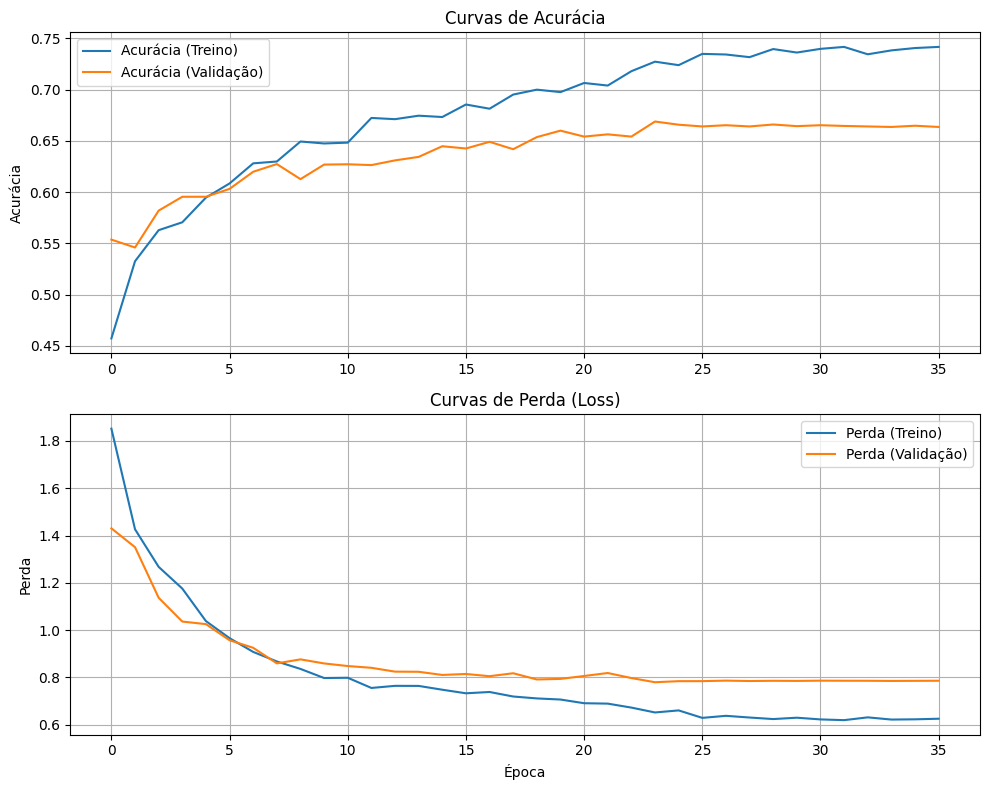

In [7]:
import matplotlib.pyplot as plt



# --- Criar a figura ---
plt.figure(figsize=(10, 8))

# --- 1. Gráfico de Acurácia ---
plt.subplot(2, 1, 1) # (2 linhas, 1 coluna, gráfico 1)
# Apenas mude 'history.history' para 'history_data'
plt.plot(history_data['accuracy'], label='Acurácia (Treino)')
plt.plot(history_data['val_accuracy'], label='Acurácia (Validação)')
plt.title('Curvas de Acurácia')
plt.ylabel('Acurácia')
plt.legend()
plt.grid(True)

# --- 2. Gráfico de Perda (Loss) ---
plt.subplot(2, 1, 2) # (2 linhas, 1 coluna, gráfico 2)
# Apenas mude 'history.history' para 'history_data'
plt.plot(history_data['loss'], label='Perda (Treino)')
plt.plot(history_data['val_loss'], label='Perda (Validação)')
plt.title('Curvas de Perda (Loss)')
plt.ylabel('Perda')
plt.xlabel('Época')
plt.legend()
plt.grid(True)

# --- Salvar a imagem ---
plt.tight_layout() # Ajusta o layout
plt.savefig('grafico_treino_1.png')

print("Gráfico salvo com sucesso!")

### Matriz Confusão

130/130 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step
--- Relatório de Classificação ---
              precision    recall  f1-score   support

    Classe 0       0.64      0.88      0.74      2070
    Classe 1       0.70      0.41      0.52      1029
    Classe 2       0.67      0.43      0.53      1041

    accuracy                           0.65      4140
   macro avg       0.67      0.57      0.59      4140
weighted avg       0.66      0.65      0.63      4140

[[1812  114  144]
 [ 522  426   81]
 [ 518   71  452]]


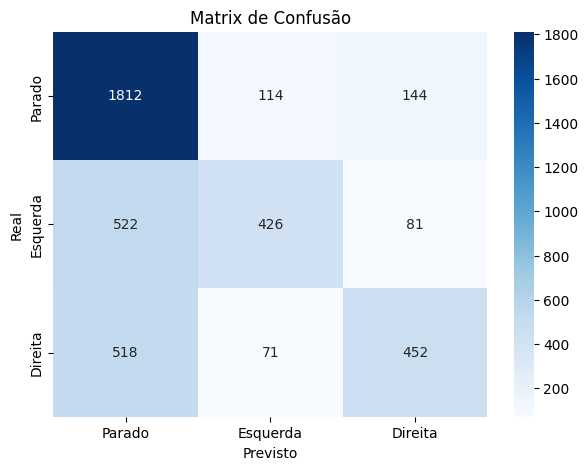


Custo Total do Modelo: 3924


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Fazer previsões
predictions = model.predict(X_test)

y_pred = np.argmax(predictions, axis=1)
true_classes = y_test if len(y_test.shape) == 1 else np.argmax(y_test, axis=1)

print("--- Relatório de Classificação ---")
print(classification_report(y_test, y_pred, target_names=['Classe 0', 'Classe 1', 'Classe 2']))

# Calcula matriz de confusão
conf_matrix = confusion_matrix(true_classes, y_pred)
print(conf_matrix)

class_names = ['Parado', 'Esquerda', 'Direita']

plt.figure(figsize=(7, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Previsto')
plt.ylabel('Real')
plt.title('Matrix de Confusão')
plt.show()


ganhador:
Custo Total do Modelo: 4596

hibrido:
Custo Total do Modelo: 5391

1.0:
--- Relatório de Classificação ---
              precision    recall  f1-score   support
    Classe 0       0.70      0.74      0.72      2070
    Classe 1       0.63      0.56      0.59      1029
    Classe 2       0.59      0.59      0.59      1041

    accuracy                           0.66      4140
   macro avg       0.64      0.63      0.63      4140
weighted avg       0.66      0.66      0.66      4140

Auto:
--- Relatório de Classificação ---
              precision    recall  f1-score   support

    Classe 0       0.70      0.66      0.68      2070
    Classe 1       0.57      0.59      0.58      1029
    Classe 2       0.54      0.58      0.56      1041

    accuracy                           0.62      4140
   macro avg       0.60      0.61      0.61      4140
weighted avg       0.63      0.62      0.63      4140

[[1372  328  370]
 [ 285  607  137]
 [ 308  129  604]]

1.5:
--- Relatório de Classificação ---
              precision    recall  f1-score   support

    Classe 0       0.70      0.74      0.72      2070
    Classe 1       0.61      0.57      0.59      1029
    Classe 2       0.57      0.54      0.56      1041

    accuracy                           0.65      4140
   macro avg       0.63      0.62      0.62      4140
weighted avg       0.64      0.65      0.64      4140

[[1525  245  300]
 [ 316  586  127]
 [ 341  133  567]]


 PARADO 1.3:
 --- Relatório de Classificação ---
              precision    recall  f1-score   support

    Classe 0       0.65      0.85      0.74      2070
    Classe 1       0.68      0.47      0.55      1029
    Classe 2       0.64      0.44      0.52      1041

    accuracy                           0.65      4140
   macro avg       0.66      0.59      0.60      4140
weighted avg       0.65      0.65      0.64      4140

[[1762  141  167]
 [ 455  483   91]
 [ 490   91  460]]


### Salva Modelo

In [120]:
nome_arquivo = '1d_CNN_mov-imag'

caminho_do_modelo = 'modelos/model_' + nome_arquivo +'.keras'
model.save(caminho_do_modelo)
print(f"Modelo salvo em: '{caminho_do_modelo}'")

Modelo salvo em: 'modelos/model_1d_CNN_mov-imag.keras'


### Modelo Hibrido (2D+1D)

In [ ]:
input_shape = [TAM_JANELA, len(CANAIS)]
num_classes = 3


model = keras.Sequential(
    [
        keras.Input(shape=input_shape),
        
        normalizer,# Camada de Normalização

        # Bloco Espacial (2D)
        layers.Reshape((input_shape[1], input_shape[0], 1)), # (canais, tempo, 1)
        
        layers.Conv2D(filters=8, kernel_size=(input_shape[1], 1)), 
        #layers.BatchNormalization(),
        layers.Activation('relu'), 
        
        layers.Reshape((input_shape[0], 8)),

        layers.Conv1D(filters=32, kernel_size=64, activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling1D(pool_size=3),
        layers.Dropout(0.3), 

        layers.Conv1D(filters=64, kernel_size=15, activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling1D(pool_size=3),
        layers.Dropout(0.5), 

        layers.Flatten(),
        
        layers.Dense(num_classes),
    ]
)

model.summary()

### DeepConvNet adp

In [ ]:
from keras.models import Sequential
from keras.layers import Input, Conv1D, Dense, Dropout, BatchNormalization, MaxPooling1D, Flatten
from keras.optimizers import Adam

def build_deepconvnet(timesteps, n_features, n_classes):
    """
    Constrói um modelo 1D CNN inspirado na arquitetura DeepConvNet para classificação de EEG.
    """
    model = Sequential()
    
    # ENTRADA
    model.add(Input(shape=(timesteps, n_features)))
    
    # CONVOLUÇÃO TEMPORAL
    model.add(Conv1D(filters=25, kernel_size=10, activation='elu', padding='same'))
    model.add(BatchNormalization())
    model.add(MaxPooling1D(pool_size=3, strides=3))
    
    #CONVOLUÇÕES PROFUNDAS
    model.add(Conv1D(filters=50, kernel_size=10, activation='elu', padding='same'))
    model.add(BatchNormalization())
    model.add(MaxPooling1D(pool_size=3, strides=3))

    model.add(Conv1D(filters=100, kernel_size=10, activation='elu', padding='same'))
    model.add(BatchNormalization())
    model.add(MaxPooling1D(pool_size=3, strides=3))

    model.add(Conv1D(filters=200, kernel_size=10, activation='elu', padding='same'))
    model.add(BatchNormalization())
    model.add(MaxPooling1D(pool_size=3, strides=3))
    
    # CLASSIFICAÇÃO
    model.add(Flatten())
    model.add(Dense(100, activation='elu'))
    model.add(Dropout(0.5))
    model.add(Dense(n_classes, activation='softmax')) # saída
    
    return model
